# Лабораторная работа  
## «Анализ данных с использованием Loginom Community»
### Реализация аналитических процедур в Google Colab

**Выполнила:** Манина В. С., группа ББИ2302, МТУСИ

**Цель работы:** освоить обработку и анализ данных для решения бизнес-задач: импорт и проверку качества данных, построение аналитических визуализаций, применение методов Data Mining и интерпретацию результатов.

В методическом пособии работа выполняется в ML-платформе **Loginom Community**. В настоящей работе те же логические этапы реализованы в Google Colab средствами Python. Такой вариант сохраняет содержание задания, но позволяет выполнить вычисления и получить воспроизводимые результаты в браузере.

### Используемые наборы данных

| Набор данных | Назначение в работе |
|---|---|
| `Financial Sample.xlsx` | анализ финансовых показателей и построение визуализаций |
| `insurance.csv` | кластеризация застрахованных лиц и прогнозирование расходов |
| `Churn_binned.csv` | классификация оттока абонентов |

Работа превышает минимальные требования задания: кроме одного выбранного узла Data Mining, в ней последовательно рассмотрены кластеризация, регрессия и классификация на наборах данных, используемых в методическом пособии.


## 1. Подключение библиотек и загрузка файлов

Для запуска в Google Colab необходимо загрузить три исходных файла при появлении окна выбора. Если файлы уже находятся в рабочей папке Colab, повторная загрузка не потребуется.


In [1]:
import warnings
warnings.filterwarnings('ignore')

from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from IPython.display import display, Markdown
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer, TransformedTargetRegressor
from sklearn.pipeline import Pipeline
from sklearn.cluster import KMeans
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.neural_network import MLPRegressor, MLPClassifier
from sklearn.metrics import (
    silhouette_score, r2_score, mean_absolute_error, mean_squared_error,
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, confusion_matrix
)

pd.set_option('display.max_columns', 40)
pd.set_option('display.float_format', lambda x: f'{x:,.2f}')

REQUIRED_FILES = ['Financial Sample.xlsx', 'insurance.csv', 'Churn_binned.csv']

def find_file(filename):
    possible_locations = [
        Path(filename),
        Path('/content') / filename,
        Path('/mnt/data') / filename
    ]
    return next((path for path in possible_locations if path.exists()), None)

paths = {name: find_file(name) for name in REQUIRED_FILES}

if any(path is None for path in paths.values()):
    try:
        from google.colab import files
        print('Загрузите файлы:', ', '.join(REQUIRED_FILES))
        files.upload()
        paths = {name: find_file(name) for name in REQUIRED_FILES}
    except ImportError:
        pass

missing_files = [name for name, path in paths.items() if path is None]
if missing_files:
    raise FileNotFoundError(
        'Не найдены файлы: ' + ', '.join(missing_files) +
        '. Загрузите их в рабочую папку ноутбука.'
    )

for name, path in paths.items():
    print(f'{name}: {path}')

Financial Sample.xlsx: Financial Sample.xlsx
insurance.csv: insurance.csv
Churn_binned.csv: Churn_binned.csv


In [2]:
def quality_report(dataframe):
    return pd.DataFrame({
        'Тип данных': dataframe.dtypes.astype(str),
        'Пропуски': dataframe.isna().sum(),
        'Доля пропусков, %': (dataframe.isna().mean() * 100).round(2),
        'Уникальные значения': dataframe.nunique(dropna=True)
    })

def print_shape_and_duplicates(dataframe, title):
    print(title)
    print(f'Количество строк: {dataframe.shape[0]:,}')
    print(f'Количество столбцов: {dataframe.shape[1]}')
    print(f'Полностью дублирующихся строк: {dataframe.duplicated().sum():,}')

# Часть I. Визуальный анализ финансовых данных

## 2. Импорт и оценка качества набора `Financial Sample.xlsx`

Набор содержит сведения о продажах продукции по странам, сегментам рынка и периодам. Он используется для воспроизведения этапов, которые в Loginom соответствуют узлу **Excel файл** и визуализаторам **Качество данных**, **Статистика**, **Куб** и **Диаграмма**.


In [3]:
financial_raw = pd.read_excel(paths['Financial Sample.xlsx'])
financial_raw.columns = financial_raw.columns.str.strip()

print_shape_and_duplicates(financial_raw, 'Исходный финансовый набор данных')
display(financial_raw.head())
display(quality_report(financial_raw))

Исходный финансовый набор данных
Количество строк: 700
Количество столбцов: 16
Полностью дублирующихся строк: 0


,Segment,Country,Product,Discount Band,Units Sold,Manufacturing Price,Sale Price,Gross Sales,Discounts,Sales,COGS,Profit,Date,Month Number,Month Name,Year
0,Government,Canada,Carretera,NaN,"1,618.50",3,20,"32,370.00",0.00,"32,370.00","16,185.00","16,185.00",2014-01-01,1,January,2014
1,Government,Germany,Carretera,NaN,"1,321.00",3,20,"26,420.00",0.00,"26,420.00","13,210.00","13,210.00",2014-01-01,1,January,2014
2,Midmarket,France,Carretera,NaN,"2,178.00",3,15,"32,670.00",0.00,"32,670.00","21,780.00","10,890.00",2014-06-01,6,June,2014
3,Midmarket,Germany,Carretera,NaN,888.00,3,15,"13,320.00",0.00,"13,320.00","8,880.00","4,440.00",2014-06-01,6,June,2014
4,Midmarket,Mexico,Carretera,NaN,"2,470.00",3,15,"37,050.00",0.00,"37,050.00","24,700.00","12,350.00",2014-06-01,6,June,2014


,Тип данных,Пропуски,"Доля пропусков, %",Уникальные значения
Segment,object,0,0.00,5
Country,object,0,0.00,5
Product,object,0,0.00,6
Discount Band,object,53,7.57,3
Units Sold,float64,0,0.00,510
Manufacturing Price,int64,0,0.00,6
Sale Price,int64,0,0.00,7
Gross Sales,float64,0,0.00,550
Discounts,float64,0,0.00,515
Sales,float64,0,0.00,559


In [4]:
missing_discount = financial_raw[financial_raw['Discount Band'].isna()]
print(f'Строк без указанной категории скидки: {len(missing_discount):,}')
print(
    'Сумма фактических скидок в этих строках: '
    f'{missing_discount["Discounts"].sum():,.2f}'
)

financial = financial_raw.copy()
financial['Discount Band'] = financial['Discount Band'].fillna('No Discount')
financial['Date'] = pd.to_datetime(financial['Date'])
financial['Year_Month'] = financial['Date'].dt.to_period('M').astype(str)

print('\nПосле содержательной обработки пустых значений:')
display(quality_report(financial))

Строк без указанной категории скидки: 53
Сумма фактических скидок в этих строках: 0.00

После содержательной обработки пустых значений:


,Тип данных,Пропуски,"Доля пропусков, %",Уникальные значения
Segment,object,0,0.00,5
Country,object,0,0.00,5
Product,object,0,0.00,6
Discount Band,object,0,0.00,4
Units Sold,float64,0,0.00,510
Manufacturing Price,int64,0,0.00,6
Sale Price,int64,0,0.00,7
Gross Sales,float64,0,0.00,550
Discounts,float64,0,0.00,515
Sales,float64,0,0.00,559


### Вывод по качеству данных

Пропуски обнаружены только в поле `Discount Band`. Проверка показывает, что для этих строк сумма скидок равна нулю. Поэтому значения не удаляются, а заменяются на категорию `No Discount`, то есть «скидка отсутствует». Такое преобразование сохраняет продажи и позволяет корректно использовать поле как измерение в сводной таблице.


## 3. Факты и измерения финансового анализа

В терминологии Loginom **факты** представляют собой количественные показатели, которые агрегируются в отчёте. **Измерения** задают направления анализа и позволяют формировать срезы.


In [5]:
facts_dimensions = pd.DataFrame({
    'Роль в анализе': ['Измерения', 'Факты'],
    'Поля': [
        'Segment, Country, Product, Discount Band, Year, Month Name',
        'Units Sold, Gross Sales, Discounts, Sales, COGS, Profit'
    ],
    'Использование': [
        'Группировка и фильтрация данных',
        'Сумма, среднее значение, доля в итоговом показателе'
    ]
})
display(facts_dimensions)

statistics_financial = financial[
    ['Units Sold', 'Gross Sales', 'Discounts', 'Sales', 'COGS', 'Profit']
].describe().T
statistics_financial['Медиана'] = financial[
    ['Units Sold', 'Gross Sales', 'Discounts', 'Sales', 'COGS', 'Profit']
].median()

display(statistics_financial.round(2))

,Роль в анализе,Поля,Использование
0,Измерения,"Segment, Country, Product, Discount Band, Year...",Группировка и фильтрация данных
1,Факты,"Units Sold, Gross Sales, Discounts, Sales, COG...","Сумма, среднее значение, доля в итоговом показ..."


,count,mean,std,min,25%,50%,75%,max,Медиана
Units Sold,700.00,"1,608.29",867.43,200.00,905.00,"1,542.50","2,229.12","4,492.50","1,542.50"
Gross Sales,700.00,"182,759.43","254,262.28","1,799.00","17,391.75","37,980.00","279,025.00","1,207,500.00","37,980.00"
Discounts,700.00,"13,150.35","22,962.93",0.00,800.32,"2,585.25","15,956.34","149,677.50","2,585.25"
Sales,700.00,"169,609.07","236,726.35","1,655.08","15,928.00","35,540.20","261,077.50","1,159,200.00","35,540.20"
COGS,700.00,"145,475.21","203,865.51",918.00,"7,490.00","22,506.25","245,607.50","950,625.00","22,506.25"
Profit,700.00,"24,133.86","42,760.63","-40,617.50","2,805.96","9,242.20","22,662.00","262,200.00","9,242.20"


## 4. Визуализатор «Куб»: сводный анализ продаж

Аналогом OLAP-куба в Python является сводная таблица `pivot_table`.  
В первой таблице измерениями являются продукт и сегмент, а фактом — сумма валовых продаж. Во второй таблице дополнительно рассчитывается доля продаж каждого продукта внутри сегмента.


In [6]:
cube_gross_sales = pd.pivot_table(
    financial,
    index='Product',
    columns='Segment',
    values='Gross Sales',
    aggfunc='sum',
    fill_value=0,
    margins=True,
    margins_name='Итого'
)

print('Куб: валовые продажи по продуктам и сегментам')
display(cube_gross_sales.round(2))

product_segment = (
    financial.groupby(['Segment', 'Product'], as_index=False)
             .agg(Gross_Sales=('Gross Sales', 'sum'),
                  Discounts=('Discounts', 'sum'),
                  Profit=('Profit', 'sum'))
)
product_segment['Gross_Sales_Part_Pct'] = (
    product_segment['Gross_Sales'] /
    product_segment.groupby('Segment')['Gross_Sales'].transform('sum') * 100
)

print('Вычисляемый факт: доля продукта в продажах своего сегмента, %')
display(
    product_segment.sort_values(['Segment', 'Gross_Sales_Part_Pct'],
                                ascending=[True, False]).round(2)
)

Куб: валовые продажи по продуктам и сегментам


Segment,Channel Partners,Enterprise,Government,Midmarket,Small Business,Итого
Product,,,,,,
Amarilla,"350,298.00","2,852,875.00","10,532,086.50","277,620.00","5,024,400.00","19,037,279.50"
Carretera,"297,732.00","3,569,187.50","6,430,801.00","364,800.00","4,275,000.00","14,937,520.50"
Montana,"277,548.00","2,756,187.50","6,088,609.00","309,540.00","7,117,950.00","16,549,834.50"
Paseo,"490,704.00","5,572,500.00","16,253,973.00","973,485.00","12,321,000.00","35,611,662.00"
VTT,"324,252.00","2,499,500.00","8,750,224.00","363,457.50","10,031,100.00","21,968,533.50"
Velo,"194,628.00","3,818,750.00","8,347,373.00","293,767.50","7,172,250.00","19,826,768.50"
Итого,"1,935,162.00","21,069,000.00","56,403,066.50","2,582,670.00","45,941,700.00","127,931,598.50"


Вычисляемый факт: доля продукта в продажах своего сегмента, %


,Segment,Product,Gross_Sales,Discounts,Profit,Gross_Sales_Part_Pct
3,Channel Partners,Paseo,"490,704.00","36,189.60","331,838.40",25.36
0,Channel Partners,Amarilla,"350,298.00","32,655.00","230,068.50",18.10
4,Channel Partners,VTT,"324,252.00","23,423.04","219,765.96",16.76
1,Channel Partners,Carretera,"297,732.00","14,893.32","208,405.68",15.39
2,Channel Partners,Montana,"277,548.00","15,703.44","192,457.56",14.34
5,Channel Partners,Velo,"194,628.00","11,703.96","134,267.04",10.06
9,Enterprise,Paseo,"5,572,500.00","304,640.00","-81,740.00",26.45
11,Enterprise,Velo,"3,818,750.00","237,512.50","-84,762.50",18.12
7,Enterprise,Carretera,"3,569,187.50","365,479.38","-222,711.88",16.94
6,Enterprise,Amarilla,"2,852,875.00","209,267.50","-95,152.50",13.54


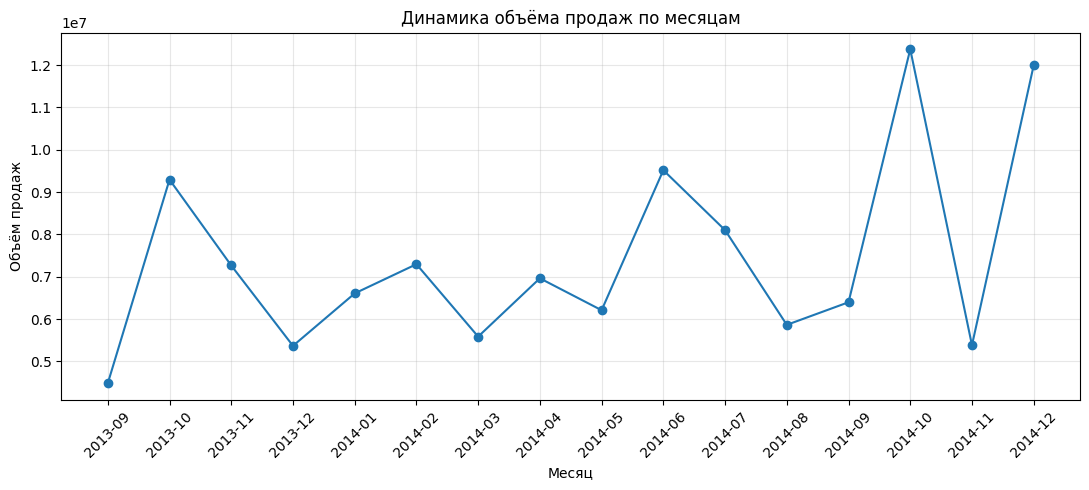

,Year_Month,Sales,Profit
0,2013-09,"4,484,000.03","763,603.03"
1,2013-10,"9,295,611.10","1,657,795.10"
2,2013-11,"7,267,203.30","765,502.30"
3,2013-12,"5,368,441.08","691,564.08"
4,2014-01,"6,607,761.68","814,028.68"
5,2014-02,"7,297,531.39","1,148,547.39"
6,2014-03,"5,586,859.87","669,866.87"
7,2014-04,"6,964,775.07","929,984.57"
8,2014-05,"6,210,211.06","828,640.06"
9,2014-06,"9,518,893.82","1,473,753.82"


In [7]:
monthly_sales = (
    financial.groupby('Year_Month', as_index=False)
             .agg(Sales=('Sales', 'sum'),
                  Profit=('Profit', 'sum'))
             .sort_values('Year_Month')
)

plt.figure(figsize=(11, 5))
plt.plot(monthly_sales['Year_Month'], monthly_sales['Sales'], marker='o')
plt.title('Динамика объёма продаж по месяцам')
plt.xlabel('Месяц')
plt.ylabel('Объём продаж')
plt.xticks(rotation=45)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

display(monthly_sales.round(2))

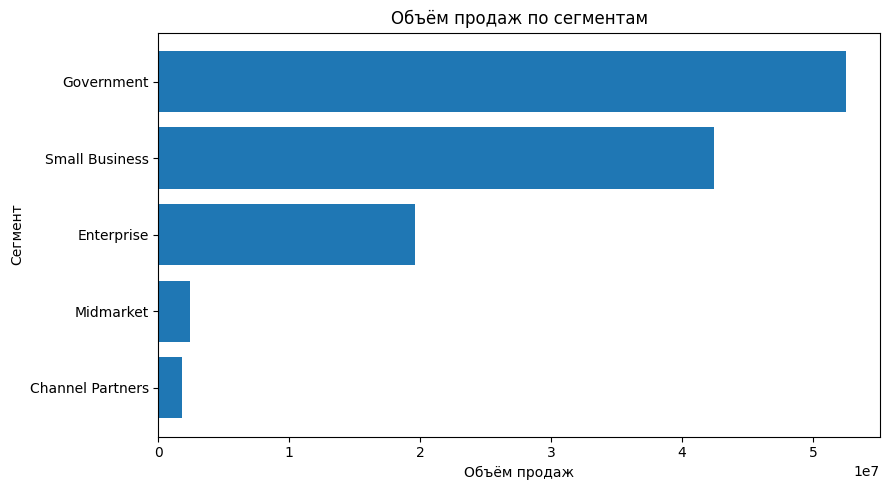

,Segment,Sales
2,Government,"52,504,260.67"
4,Small Business,"42,427,918.50"
1,Enterprise,"19,611,694.38"
3,Midmarket,"2,381,883.08"
0,Channel Partners,"1,800,593.64"


In [8]:
sales_by_segment = (
    financial.groupby('Segment', as_index=False)
             .agg(Sales=('Sales', 'sum'))
             .sort_values('Sales')
)

plt.figure(figsize=(9, 5))
plt.barh(sales_by_segment['Segment'], sales_by_segment['Sales'])
plt.title('Объём продаж по сегментам')
plt.xlabel('Объём продаж')
plt.ylabel('Сегмент')
plt.tight_layout()
plt.show()

display(sales_by_segment.sort_values('Sales', ascending=False).round(2))

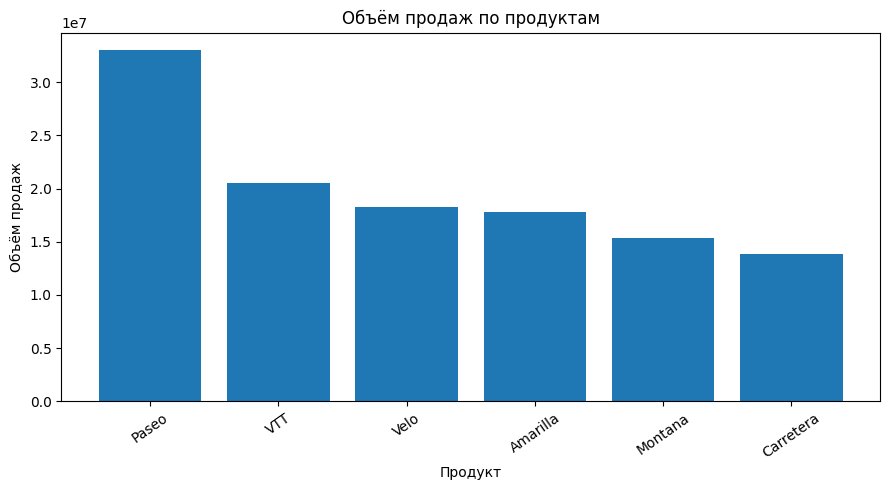

,Product,Sales,Profit
3,Paseo,"33,011,143.95","4,797,437.95"
4,VTT,"20,511,921.02","3,034,608.02"
5,Velo,"18,250,059.46","2,305,992.46"
0,Amarilla,"17,747,116.06","2,814,104.06"
2,Montana,"15,390,801.88","2,114,754.88"
1,Carretera,"13,815,307.88","1,826,804.88"


In [9]:
top_products = (
    financial.groupby('Product', as_index=False)
             .agg(Sales=('Sales', 'sum'),
                  Profit=('Profit', 'sum'))
             .sort_values('Sales', ascending=False)
)

plt.figure(figsize=(9, 5))
plt.bar(top_products['Product'], top_products['Sales'])
plt.title('Объём продаж по продуктам')
plt.xlabel('Продукт')
plt.ylabel('Объём продаж')
plt.xticks(rotation=35)
plt.tight_layout()
plt.show()

display(top_products.round(2))

### Интерпретация финансового анализа

Построенные срезы показывают структуру продаж по сегментам и продуктам, а динамический ряд позволяет обнаружить месяцы с увеличением или снижением объёма реализации. Для бизнеса такие сведения полезны при корректировке ассортиментной политики, планировании скидок и сравнении результативности отдельных рыночных сегментов.


# Часть II. Data Mining на данных медицинского страхования

## 5. Импорт и проверка качества набора `insurance.csv`

Набор описывает застрахованных лиц и включает возраст, пол, индекс массы тела, число детей, признак курения, регион проживания и расходы на медицинское обслуживание (`charges`).


In [10]:
insurance_raw = pd.read_csv(paths['insurance.csv'])

print_shape_and_duplicates(insurance_raw, 'Исходный набор страховых данных')
display(insurance_raw.head())
display(quality_report(insurance_raw))

insurance = insurance_raw.drop_duplicates().reset_index(drop=True)
print(f'После удаления дубликатов осталось строк: {len(insurance):,}')

Исходный набор страховых данных
Количество строк: 1,338
Количество столбцов: 7
Полностью дублирующихся строк: 1


,age,sex,bmi,children,smoker,region,charges
0,19,female,27.90,0,yes,southwest,"16,884.92"
1,18,male,33.77,1,no,southeast,"1,725.55"
2,28,male,33.00,3,no,southeast,"4,449.46"
3,33,male,22.70,0,no,northwest,"21,984.47"
4,32,male,28.88,0,no,northwest,"3,866.86"


,Тип данных,Пропуски,"Доля пропусков, %",Уникальные значения
age,int64,0,0.00,47
sex,object,0,0.00,2
bmi,float64,0,0.00,548
children,int64,0,0.00,6
smoker,object,0,0.00,2
region,object,0,0.00,4
charges,float64,0,0.00,1337


После удаления дубликатов осталось строк: 1,337


## 6. Узел Data Mining «Кластеризация»

В соответствии с примером из методического пособия число кластеров задаётся равным **3**, а поле `charges` не участвует в построении групп. Оно используется после обучения только для содержательного описания полученных кластеров.

В Loginom на этом этапе используется алгоритм `k-means`. В Colab ему соответствует класс `KMeans`. Строковые признаки кодируются, а числовые стандартизируются, поскольку Python-модель работает с числовой матрицей признаков.


In [11]:
cluster_inputs = ['age', 'sex', 'bmi', 'children', 'smoker', 'region']
cluster_numeric = ['age', 'bmi', 'children']
cluster_categorical = ['sex', 'smoker', 'region']

cluster_preprocessor = ColumnTransformer([
    ('numeric', StandardScaler(), cluster_numeric),
    ('categorical', OneHotEncoder(handle_unknown='ignore'), cluster_categorical)
])

X_cluster = cluster_preprocessor.fit_transform(insurance[cluster_inputs])

cluster_model = KMeans(n_clusters=3, n_init=20, random_state=42)
insurance['Cluster'] = cluster_model.fit_predict(X_cluster)

silhouette = silhouette_score(X_cluster, insurance['Cluster'])
print(f'Silhouette score для разбиения на 3 кластера: {silhouette:.3f}')

cluster_profile = (
    insurance.groupby('Cluster')
             .agg(
                 Количество_застрахованных=('charges', 'size'),
                 Средний_возраст=('age', 'mean'),
                 Средний_BMI=('bmi', 'mean'),
                 Среднее_число_детей=('children', 'mean'),
                 Доля_курящих=('smoker', lambda series: (series == 'yes').mean() * 100),
                 Средние_расходы=('charges', 'mean')
             )
             .round(2)
)

display(cluster_profile)

Silhouette score для разбиения на 3 кластера: 0.184


,Количество_застрахованных,Средний_возраст,Средний_BMI,Среднее_число_детей,Доля_курящих,Средние_расходы
Cluster,,,,,,
0,396,40.45,30.95,2.66,22.47,"14,734.56"
1,454,52.77,31.51,0.44,17.40,"16,016.14"
2,487,25.59,29.64,0.44,21.77,"9,544.09"


In [12]:
cluster_gender = pd.crosstab(
    insurance['Cluster'],
    insurance['sex'],
    normalize='index'
).mul(100).round(2)

cluster_region = pd.crosstab(
    insurance['Cluster'],
    insurance['region'],
    normalize='index'
).mul(100).round(2)

print('Структура кластеров по полу, %')
display(cluster_gender)
print('Структура кластеров по региону, %')
display(cluster_region)

Структура кластеров по полу, %


sex,female,male
Cluster,,
0,47.22,52.78
1,51.54,48.46
2,49.49,50.51


Структура кластеров по региону, %


region,northeast,northwest,southeast,southwest
Cluster,,,,
0,22.22,27.53,25.25,25.00
1,25.11,22.03,26.87,25.99
2,25.05,23.61,29.16,22.18


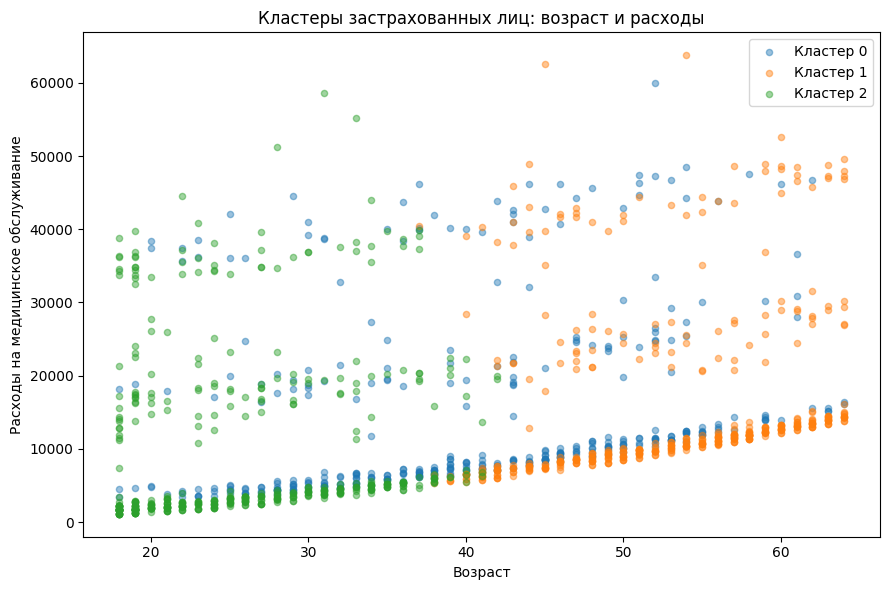

In [13]:
plt.figure(figsize=(9, 6))
for cluster_number in sorted(insurance['Cluster'].unique()):
    group = insurance[insurance['Cluster'] == cluster_number]
    plt.scatter(
        group['age'],
        group['charges'],
        label=f'Кластер {cluster_number}',
        alpha=0.45,
        s=20
    )

plt.title('Кластеры застрахованных лиц: возраст и расходы')
plt.xlabel('Возраст')
plt.ylabel('Расходы на медицинское обслуживание')
plt.legend()
plt.tight_layout()
plt.show()

In [14]:
highest_cost_cluster = cluster_profile['Средние_расходы'].idxmax()
lowest_cost_cluster = cluster_profile['Средние_расходы'].idxmin()

display(Markdown(
    f'''### Вывод по кластеризации

Наиболее высокие средние медицинские расходы выявлены в **кластере {highest_cost_cluster}**:
{cluster_profile.loc[highest_cost_cluster, "Средние_расходы"]:,.2f}.  
Наименьший средний уровень расходов характерен для **кластера {lowest_cost_cluster}**:
{cluster_profile.loc[lowest_cost_cluster, "Средние_расходы"]:,.2f}.

Поле `charges` не использовалось при формировании групп, поэтому полученное различие можно рассматривать как результат различий профилей застрахованных по возрасту, BMI, семейной нагрузке, курению, полу и региону. Для страховой организации такая сегментация полезна при анализе клиентского портфеля и предварительной оценке групп риска.'''
))

### Вывод по кластеризации

Наиболее высокие средние медицинские расходы выявлены в **кластере 1**:
16,016.14.  
Наименьший средний уровень расходов характерен для **кластера 2**:
9,544.09.

Поле `charges` не использовалось при формировании групп, поэтому полученное различие можно рассматривать как результат различий профилей застрахованных по возрасту, BMI, семейной нагрузке, курению, полу и региону. Для страховой организации такая сегментация полезна при анализе клиентского портфеля и предварительной оценке групп риска.

## 7. Дополнительный анализ: линейная регрессия и нейросеть для прогноза расходов

В этой части целевой показатель — `charges`. Модели обучаются на части наблюдений, а качество прогноза проверяется на тестовой выборке. Для сравнения используются коэффициент детерминации \(R^2\), средняя абсолютная ошибка `MAE` и среднеквадратическая ошибка `RMSE`.


In [15]:
regression_X = insurance.drop(columns=['charges', 'Cluster'])
regression_y = insurance['charges']

regression_numeric = ['age', 'bmi', 'children']
regression_categorical = ['sex', 'smoker', 'region']

regression_preprocessor = ColumnTransformer([
    ('numeric', StandardScaler(), regression_numeric),
    ('categorical', OneHotEncoder(handle_unknown='ignore'), regression_categorical)
])

X_train_reg, X_test_reg, y_train_reg, y_test_reg = train_test_split(
    regression_X, regression_y, test_size=0.25, random_state=42
)

linear_model = Pipeline([
    ('preprocessor', regression_preprocessor),
    ('model', LinearRegression())
])

neural_regression_pipeline = Pipeline([
    ('preprocessor', regression_preprocessor),
    ('model', MLPRegressor(
        hidden_layer_sizes=(50, 25, 10),
        max_iter=3000,
        early_stopping=True,
        learning_rate_init=0.005,
        random_state=42
    ))
])

neural_model = TransformedTargetRegressor(
    regressor=neural_regression_pipeline,
    transformer=StandardScaler()
)

linear_model.fit(X_train_reg, y_train_reg)
neural_model.fit(X_train_reg, y_train_reg)

prediction_linear = linear_model.predict(X_test_reg)
prediction_neural = neural_model.predict(X_test_reg)

def regression_metrics(name, actual, predicted):
    return {
        'Модель': name,
        'R2': r2_score(actual, predicted),
        'MAE': mean_absolute_error(actual, predicted),
        'RMSE': mean_squared_error(actual, predicted) ** 0.5
    }

regression_results = pd.DataFrame([
    regression_metrics('Линейная регрессия', y_test_reg, prediction_linear),
    regression_metrics('Нейросеть (регрессия)', y_test_reg, prediction_neural)
])

display(regression_results.round(3))

,Модель,R2,MAE,RMSE
0,Линейная регрессия,0.80,"4,069.04","5,940.03"
1,Нейросеть (регрессия),0.88,"2,750.83","4,532.27"


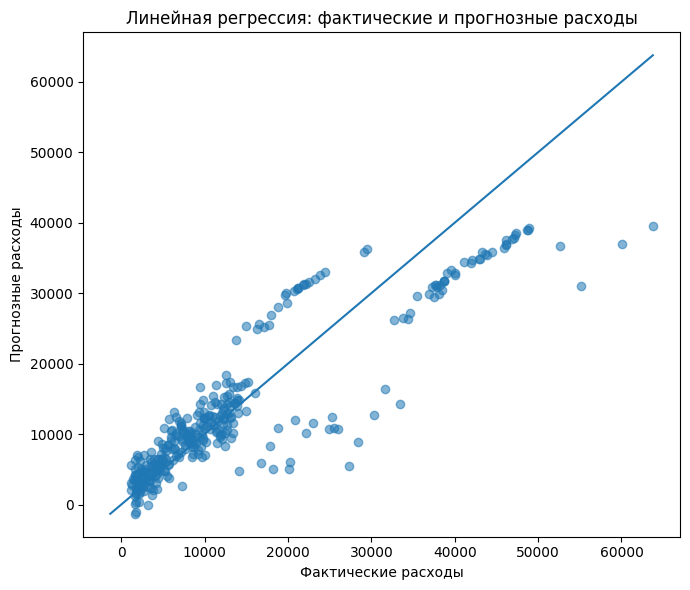

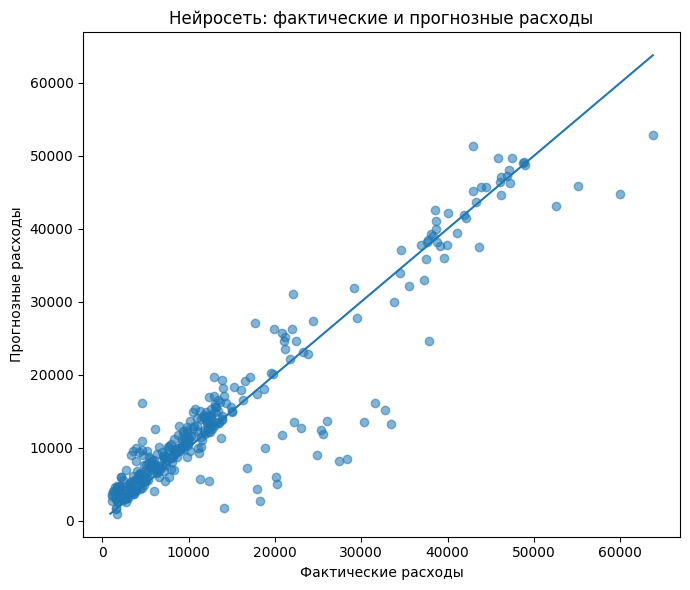

In [16]:
plt.figure(figsize=(7, 6))
plt.scatter(y_test_reg, prediction_linear, alpha=0.55)
minimum = min(y_test_reg.min(), prediction_linear.min())
maximum = max(y_test_reg.max(), prediction_linear.max())
plt.plot([minimum, maximum], [minimum, maximum])
plt.title('Линейная регрессия: фактические и прогнозные расходы')
plt.xlabel('Фактические расходы')
plt.ylabel('Прогнозные расходы')
plt.tight_layout()
plt.show()

plt.figure(figsize=(7, 6))
plt.scatter(y_test_reg, prediction_neural, alpha=0.55)
minimum = min(y_test_reg.min(), prediction_neural.min())
maximum = max(y_test_reg.max(), prediction_neural.max())
plt.plot([minimum, maximum], [minimum, maximum])
plt.title('Нейросеть: фактические и прогнозные расходы')
plt.xlabel('Фактические расходы')
plt.ylabel('Прогнозные расходы')
plt.tight_layout()
plt.show()

In [17]:
best_regression = regression_results.sort_values('R2', ascending=False).iloc[0]

display(Markdown(
    f'''### Вывод по прогнозированию расходов

На тестовой выборке лучший результат по показателю \(R^2\) показала модель
**{best_regression["Модель"]}**: \(R^2 = {best_regression["R2"]:.3f}\),
`MAE = {best_regression["MAE"]:,.2f}`, `RMSE = {best_regression["RMSE"]:,.2f}`.

Модель может использоваться как аналитическая основа для предварительной оценки расходов, однако результат не следует трактовать как окончательное страховое решение без дополнительной проверки факторов риска и качества исходных данных.'''
))

### Вывод по прогнозированию расходов

На тестовой выборке лучший результат по показателю \(R^2\) показала модель
**Нейросеть (регрессия)**: \(R^2 = 0.881\),
`MAE = 2,750.83`, `RMSE = 4,532.27`.

Модель может использоваться как аналитическая основа для предварительной оценки расходов, однако результат не следует трактовать как окончательное страховое решение без дополнительной проверки факторов риска и качества исходных данных.

# Часть III. Классификация оттока клиентов

## 8. Импорт и оценка качества набора `Churn_binned.csv`

Набор данных отражает характеристики абонентов сотового оператора. Целевое поле `churn` показывает, остаётся клиент или уходит. Задача классификации состоит в выявлении клиентов с повышенной вероятностью оттока.


Исходный набор данных об оттоке
Количество строк: 4,431
Количество столбцов: 10
Полностью дублирующихся строк: 2,890


,longdist,local,int_disc,billtype,pay,gender,marital,incomecat,agecat,churn
0,<2,<8,Нет,Бюджетный,CC,Мужской,Женат,<15,<31,Уходит
1,<2,<8,Нет,Бесплатный,CC,Мужской,Женат,<15,<31,Уходит
2,<2,<8,Нет,Бесплатный,CC,Мужской,Женат,<15,<31,Уходит
3,<2,<8,Нет,Бесплатный,CH,Мужской,Одинокий,<15,<31,Остается
4,<2,<8,Нет,Бесплатный,Auto,Мужской,Одинокий,<15,<31,Уходит


,Тип данных,Пропуски,"Доля пропусков, %",Уникальные значения
longdist,object,0,0.00,5
local,object,0,0.00,5
int_disc,object,0,0.00,2
billtype,object,0,0.00,2
pay,object,0,0.00,3
gender,object,0,0.00,2
marital,object,0,0.00,2
incomecat,object,0,0.00,5
agecat,object,0,0.00,5
churn,object,0,0.00,2


,Статус,Количество,"Доля, %"
0,Остается,2496,56.33
1,Уходит,1935,43.67


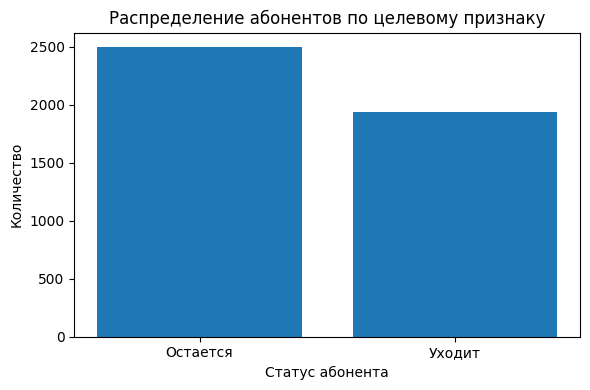

In [18]:
churn = pd.read_csv(paths['Churn_binned.csv'], sep=';', encoding='cp1251')

print_shape_and_duplicates(churn, 'Исходный набор данных об оттоке')
display(churn.head())
display(quality_report(churn))

churn_distribution = churn['churn'].value_counts().rename_axis('Статус').reset_index(name='Количество')
churn_distribution['Доля, %'] = (
    churn_distribution['Количество'] / len(churn) * 100
).round(2)

display(churn_distribution)

plt.figure(figsize=(6, 4))
plt.bar(churn_distribution['Статус'], churn_distribution['Количество'])
plt.title('Распределение абонентов по целевому признаку')
plt.xlabel('Статус абонента')
plt.ylabel('Количество')
plt.tight_layout()
plt.show()

## 9. Логистическая регрессия и нейросеть для классификации

Все поля, кроме `churn`, рассматриваются как входные признаки. Целевое значение кодируется следующим образом: `1` — клиент уходит, `0` — клиент остаётся. Качество оценивается на тестовой выборке по показателям `Accuracy`, `Precision`, `Recall`, `F1` и `ROC-AUC`.


In [19]:
churn_model_data = churn.copy()
churn_model_data['Target'] = (churn_model_data['churn'] == 'Уходит').astype(int)

classification_X = churn_model_data.drop(columns=['churn', 'Target'])
classification_y = churn_model_data['Target']
classification_features = classification_X.columns.tolist()

classification_preprocessor = ColumnTransformer([
    ('categorical', OneHotEncoder(handle_unknown='ignore'), classification_features)
])

X_train_cls, X_test_cls, y_train_cls, y_test_cls = train_test_split(
    classification_X,
    classification_y,
    test_size=0.25,
    stratify=classification_y,
    random_state=42
)

logistic_model = Pipeline([
    ('preprocessor', classification_preprocessor),
    ('model', LogisticRegression(
        max_iter=1000,
        class_weight='balanced',
        random_state=42
    ))
])

neural_classification_model = Pipeline([
    ('preprocessor', classification_preprocessor),
    ('model', MLPClassifier(
        hidden_layer_sizes=(20, 10),
        max_iter=1000,
        early_stopping=True,
        random_state=42
    ))
])

logistic_model.fit(X_train_cls, y_train_cls)
neural_classification_model.fit(X_train_cls, y_train_cls)

prediction_logistic = logistic_model.predict(X_test_cls)
probability_logistic = logistic_model.predict_proba(X_test_cls)[:, 1]

prediction_neural_cls = neural_classification_model.predict(X_test_cls)
probability_neural_cls = neural_classification_model.predict_proba(X_test_cls)[:, 1]

def classification_metrics(name, actual, predicted, probability):
    return {
        'Модель': name,
        'Accuracy': accuracy_score(actual, predicted),
        'Precision': precision_score(actual, predicted),
        'Recall': recall_score(actual, predicted),
        'F1': f1_score(actual, predicted),
        'ROC-AUC': roc_auc_score(actual, probability)
    }

classification_results = pd.DataFrame([
    classification_metrics(
        'Логистическая регрессия',
        y_test_cls,
        prediction_logistic,
        probability_logistic
    ),
    classification_metrics(
        'Нейросеть (классификация)',
        y_test_cls,
        prediction_neural_cls,
        probability_neural_cls
    )
])

display(classification_results.round(3))

,Модель,Accuracy,Precision,Recall,F1,ROC-AUC
0,Логистическая регрессия,0.74,0.66,0.83,0.74,0.81
1,Нейросеть (классификация),0.78,0.74,0.79,0.76,0.85


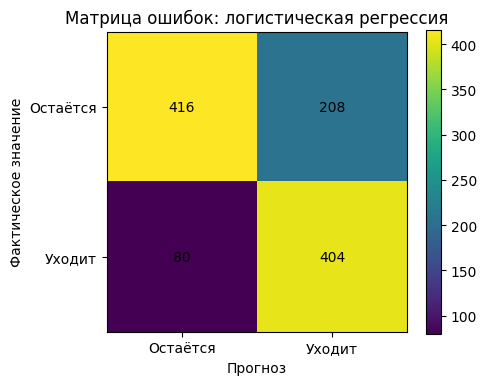

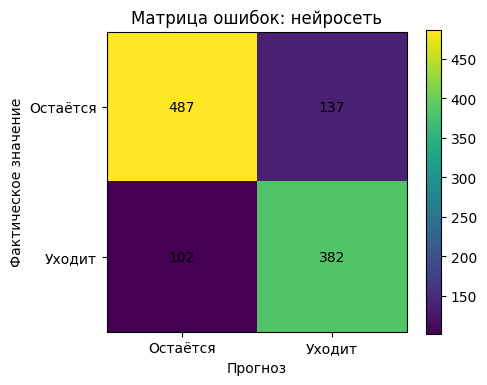

In [20]:
def show_confusion_matrix(matrix, title):
    plt.figure(figsize=(5, 4))
    plt.imshow(matrix)
    plt.title(title)
    plt.xlabel('Прогноз')
    plt.ylabel('Фактическое значение')
    plt.xticks([0, 1], ['Остаётся', 'Уходит'])
    plt.yticks([0, 1], ['Остаётся', 'Уходит'])
    for row in range(2):
        for column in range(2):
            plt.text(column, row, matrix[row, column], ha='center', va='center')
    plt.colorbar()
    plt.tight_layout()
    plt.show()

confusion_logistic = confusion_matrix(y_test_cls, prediction_logistic)
confusion_neural = confusion_matrix(y_test_cls, prediction_neural_cls)

show_confusion_matrix(
    confusion_logistic,
    'Матрица ошибок: логистическая регрессия'
)
show_confusion_matrix(
    confusion_neural,
    'Матрица ошибок: нейросеть'
)

In [21]:
encoder = logistic_model.named_steps['preprocessor'].named_transformers_['categorical']
feature_names = encoder.get_feature_names_out(classification_features)
coefficients = logistic_model.named_steps['model'].coef_[0]

importance = pd.DataFrame({
    'Признак': feature_names,
    'Коэффициент': coefficients
}).sort_values('Коэффициент', ascending=False)

print('Признаки, сильнее связанные с прогнозом ухода клиента')
display(importance.head(10).round(3))

print('Признаки, сильнее связанные с прогнозом сохранения клиента')
display(importance.tail(10).sort_values('Коэффициент').round(3))

Признаки, сильнее связанные с прогнозом ухода клиента


,Признак,Коэффициент
4,longdist_<2,1.24
17,gender_Женский,1.20
9,local_<8,0.64
21,incomecat_15-35,0.39
28,agecat_59-70,0.32
25,incomecat_<15,0.25
27,agecat_46-58,0.23
16,pay_CH,0.08
12,billtype_Бесплатный,0.03
11,int_disc_Нет,0.03


Признаки, сильнее связанные с прогнозом сохранения клиента


,Признак,Коэффициент
18,gender_Мужской,-1.19
26,agecat_31-45,-0.50
0,longdist_15-20,-0.47
3,longdist_9--14,-0.31
24,incomecat_66+,-0.27
2,longdist_21+,-0.27
8,local_8--20,-0.26
7,local_56+,-0.23
23,incomecat_51-65,-0.21
1,longdist_2--8,-0.19


In [22]:
best_classifier = classification_results.sort_values('ROC-AUC', ascending=False).iloc[0]

display(Markdown(
    f'''### Вывод по классификации оттока

Лучшее качество различения уходящих и остающихся абонентов по метрике `ROC-AUC`
показала модель **{best_classifier["Модель"]}**:
`ROC-AUC = {best_classifier["ROC-AUC"]:.3f}`, `F1 = {best_classifier["F1"]:.3f}`.

Практическая ценность классификации состоит в том, что оператор может выделить
группу клиентов с повышенным риском ухода и направить на неё удерживающие
мероприятия: персональные предложения, пересмотр тарифа или коммуникацию
с клиентской службой.'''
))

### Вывод по классификации оттока

Лучшее качество различения уходящих и остающихся абонентов по метрике `ROC-AUC`
показала модель **Нейросеть (классификация)**:
`ROC-AUC = 0.849`, `F1 = 0.762`.

Практическая ценность классификации состоит в том, что оператор может выделить
группу клиентов с повышенным риском ухода и направить на неё удерживающие
мероприятия: персональные предложения, пересмотр тарифа или коммуникацию
с клиентской службой.

## 10. Экспорт результатов

В результате выполнения ноутбука создаются три файла:

- `financial_prepared.csv` — очищенные финансовые данные для построения дополнительных отчётов;
- `insurance_clusters.csv` — данные о застрахованных с присвоенными кластерами;
- `churn_predictions.csv` — тестовые наблюдения с прогнозом вероятности ухода клиента.


In [23]:
financial_export = financial.copy()
financial_export['Date'] = financial_export['Date'].dt.strftime('%Y-%m-%d')
financial_export.to_csv('financial_prepared.csv', index=False, encoding='utf-8-sig')

insurance.to_csv('insurance_clusters.csv', index=False, encoding='utf-8-sig')

churn_predictions = X_test_cls.copy()
churn_predictions['Actual_Churn'] = y_test_cls.map({0: 'Остаётся', 1: 'Уходит'}).values
churn_predictions['Logistic_Probability_Churn'] = probability_logistic
churn_predictions['Logistic_Prediction'] = pd.Series(prediction_logistic).map({0: 'Остаётся', 1: 'Уходит'}).values
churn_predictions['Neural_Probability_Churn'] = probability_neural_cls
churn_predictions['Neural_Prediction'] = pd.Series(prediction_neural_cls).map({0: 'Остаётся', 1: 'Уходит'}).values
churn_predictions.to_csv('churn_predictions.csv', index=False, encoding='utf-8-sig')

print('Созданы файлы:')
print('- financial_prepared.csv')
print('- insurance_clusters.csv')
print('- churn_predictions.csv')

Созданы файлы:
- financial_prepared.csv
- insurance_clusters.csv
- churn_predictions.csv


# Заключение

В ходе лабораторной работы были выполнены основные этапы анализа данных, представленные в методическом пособии по Loginom Community.

На финансовом наборе данных проведена проверка качества и построены аналитические срезы, соответствующие визуализаторам «Статистика», «Куб» и «Диаграмма». Пустые значения категории скидки были содержательно интерпретированы как отсутствие скидки, поскольку в соответствующих строках фактические скидки равны нулю.

На данных медицинского страхования использован метод кластеризации. Группы сформированы на основе характеристик застрахованных лиц, а расходы применены для последующей интерпретации сегментов. Дополнительно построены две модели прогнозирования расходов, что позволяет сравнить линейный и нелинейный подходы.

На данных об абонентах решена задача классификации оттока с применением логистической регрессии и нейросети. Полученные метрики и матрицы ошибок позволяют оценить применимость моделей для выделения клиентов, которым необходимы удерживающие предложения.

Следовательно, методы бизнес-аналитики и Data Mining позволяют перейти от описания исходных данных к решению практических задач: анализу продаж, сегментации страхового портфеля, прогнозированию затрат и предупреждению клиентского оттока.


# Ответы на контрольные вопросы

**1. Как произвести импорт данных?**  
В Loginom импорт выполняется с помощью узлов «Excel файл» или «Текстовый файл». В Google Colab аналогичные операции выполняются командами `pd.read_excel()` и `pd.read_csv()`. Для `Churn_binned.csv` дополнительно указаны разделитель `;` и кодировка `cp1251`.

**2. Как настраиваются визуализаторы для узла?**  
В Loginom визуализаторы добавляются к выходному набору данных выбранного узла. В работе их аналогами стали: сводные таблицы `pivot_table` для визуализатора «Куб», таблицы описательных статистик для визуализатора «Статистика» и графики `matplotlib` для диаграмм.

**3. Чем отличаются факты и измерения? Какие типы и виды данных используются?**  
Факты — количественные показатели, которые можно агрегировать, например `Gross Sales`, `Discounts`, `Profit`, `charges`. Измерения — категориальные признаки для группировки и фильтрации, например `Segment`, `Product`, `Country`, `sex`, `region`. В Loginom выделяются логический, дата/время, вещественный, целый и строковый типы данных; виды данных — непрерывные и дискретные.

**4. Как настроен узел Data Mining?**  
Основным узлом Data Mining в работе является кластеризация страховых данных. Использован алгоритм `k-means` с тремя кластерами. Входными полями выступают `age`, `sex`, `bmi`, `children`, `smoker`, `region`. Поле `charges` исключено из построения кластеров и используется для интерпретации. В Loginom узел получает входной набор данных и формирует выходы с распределением наблюдений по кластерам и с центрами кластеров. Для интерпретации целесообразны таблица профилей кластеров и диаграмма рассеяния.

**5. Какую ценность для бизнеса можно извлечь из анализа?**  
Финансовый набор позволяет контролировать структуру и динамику продаж. Сегментация страховых клиентов помогает выявлять группы с разной ожидаемой нагрузкой по расходам. Модели оттока позволяют заранее находить абонентов, для которых особенно важны удерживающие мероприятия.


## Скачивание выгрузок в Google Colab

После выполнения всего ноутбука запустите ячейку ниже, чтобы скачать сформированные CSV-файлы.


In [24]:
try:
    from google.colab import files
    files.download('financial_prepared.csv')
    files.download('insurance_clusters.csv')
    files.download('churn_predictions.csv')
except ImportError:
    print('Файлы находятся в рабочей папке ноутбука:')
    print('- financial_prepared.csv')
    print('- insurance_clusters.csv')
    print('- churn_predictions.csv')

Файлы находятся в рабочей папке ноутбука:
- financial_prepared.csv
- insurance_clusters.csv
- churn_predictions.csv
